# ЛР 9. Классификация

Модель оценивает вероятность того, что квартиру в Астане сдадут за 14 дней (`rented_14 = 1`). Данные лежат в `data/astana_rent_class.csv`. Это 600 объявлений, структура та же, что в ЛР 8, плюс число фотографий `photos` и цель `rented_14`. Пропуски в `area`, `floor`, `year` и `furniture` заполняет Pipeline.

## Шаг 2. Загрузка и стратифицированное разбиение

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/astana_rent_class.csv")
print(df.shape)
print(df["rented_14"].value_counts(normalize=True).round(3))

train, test = train_test_split(df, test_size=0.25, random_state=42,
                               stratify=df["rented_14"])
print(train.shape, test.shape)
print(train["rented_14"].mean().round(3), test["rented_14"].mean().round(3))

(600, 13)
rented_14
0    0.658
1    0.342
Name: proportion, dtype: float64
(450, 13) (150, 13)
0.342 0.34


**Вывод.** За 14 дней сдаётся 34,2 % квартир, остальные 65,8 % нет. Классы несбалансированы. Благодаря `stratify` доля класса 1 почти одинакова в обучении (0,342) и в тесте (0,340).

## Шаг 3. Базовая модель: константа

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

num_cols = ["rooms", "area", "floor", "floors", "year", "dist_center", "price", "photos"]
cat_cols = ["district", "furniture"]
X_train, y_train = train[num_cols + cat_cols], train["rented_14"]
X_test, y_test = test[num_cols + cat_cols], test["rented_14"]

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("accuracy", round(accuracy_score(y_test, dummy.predict(X_test)), 3))

accuracy 0.66


**Вывод.** Модель, которая всегда отвечает «не сдастся», права в 66 % случаев, но не находит ни одной быстрой сделки. Это нижняя планка. Accuracy при несбалансированных классах почти ничего не говорит о качестве.

## Шаг 4. Логистическая регрессия в Pipeline

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"),
                   OneHotEncoder(handle_unknown="ignore")), cat_cols))
model = make_pipeline(prep, LogisticRegression())

scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
print(scores.round(3), scores.mean().round(3))
model.fit(X_train, y_train)
print("test accuracy", round(model.score(X_test, y_test), 3))
print(model.predict_proba(X_test[:3]).round(2))
print(model.predict(X_test[:3]))

[0.767 0.744 0.767 0.767 0.744] 0.758
test accuracy 0.72
[[0.26 0.74]
 [0.63 0.37]
 [0.85 0.15]]
[1 0 0]


`predict_proba` даёт две вероятности на объект, для класса 0 и класса 1, в сумме 1. `predict` сравнивает вероятность класса 1 с порогом 0,5. У первой квартиры 0,74, прогноз «сдастся». У второй 0,37, прогноз «не сдастся». Accuracy на кросс-валидации 0,758 против 0,66 у константы.

In [4]:
names = [n.split("__")[1] for n in model[:-1].get_feature_names_out()]
coefs = pd.Series(model[-1].coef_[0], index=names)
print(coefs.round(2).sort_values())

price               -2.65
district_Байконур   -0.75
district_Алматы     -0.58
furniture_no        -0.41
district_Сарыарка   -0.40
floors              -0.23
dist_center         -0.14
rooms               -0.10
floor                0.09
district_Нура        0.16
year                 0.32
furniture_yes        0.41
photos               0.62
district_Есиль       1.56
area                 2.29
dtype: float64


**Вывод.**
- Самые большие веса у цены (−2,65) и площади (+2,29), и знаки у них разные. При той же площади дорогая квартира сдаётся хуже, при той же цене большая сдаётся лучше. По сути модель смотрит на цену за квадратный метр.
- Фотографии, мебель и район Есиль повышают шансы. Вес фотографий 0,62, e^0,62 ≈ 1,9. Примерно 6 лишних фото, одно стандартное отклонение, почти удваивают шансы быстрой сдачи.

## Шаг 5. Матрица ошибок, precision, recall, F1

In [5]:
from sklearn.metrics import confusion_matrix, classification_report

pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred)
print(cm)
print(classification_report(y_test, pred, digits=3))

[[84 15]
 [27 24]]
              precision    recall  f1-score   support

           0      0.757     0.848     0.800        99
           1      0.615     0.471     0.533        51

    accuracy                          0.720       150
   macro avg      0.686     0.660     0.667       150
weighted avg      0.709     0.720     0.709       150



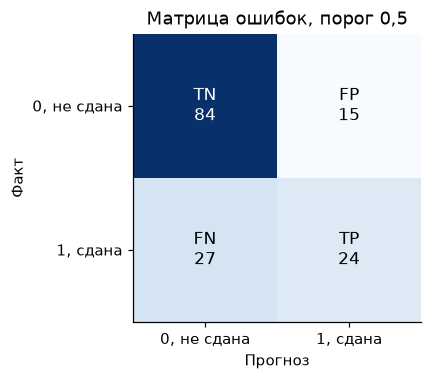

In [6]:
fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues")
labels = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center",
                color="white" if cm[i, j] > 50 else "black", fontsize=11)
ax.set_xticks([0, 1], ["0, не сдана", "1, сдана"])
ax.set_yticks([0, 1], ["0, не сдана", "1, сдана"])
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
ax.set_title("Матрица ошибок, порог 0,5")
plt.show()

**Вывод.** Строки матрицы это факт, столбцы это прогноз. Из 51 быстро сданной квартиры модель нашла 24, recall = 24 / 51 = 0,47. Из 39 квартир, про которые модель сказала «сдастся», права в 24 случаях, precision = 24 / 39 = 0,62. Accuracy 0,72 скрывала главное. Больше половины быстрых сделок модель пропускает.

## Шаг 6. Порог и ROC-AUC

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve

proba = model.predict_proba(X_test)[:, 1]
for t in [0.3, 0.5, 0.7]:
    p = (proba >= t).astype(int)
    print(t, "precision", round(precision_score(y_test, p), 3),
          "recall", round(recall_score(y_test, p), 3),
          "f1", round(f1_score(y_test, p), 3))
print("ROC-AUC", round(roc_auc_score(y_test, proba), 3))

0.3 precision 0.526 recall 0.784 f1 0.63
0.5 precision 0.615 recall 0.471 f1 0.533
0.7 precision 0.727 recall 0.157 f1 0.258
ROC-AUC 0.786


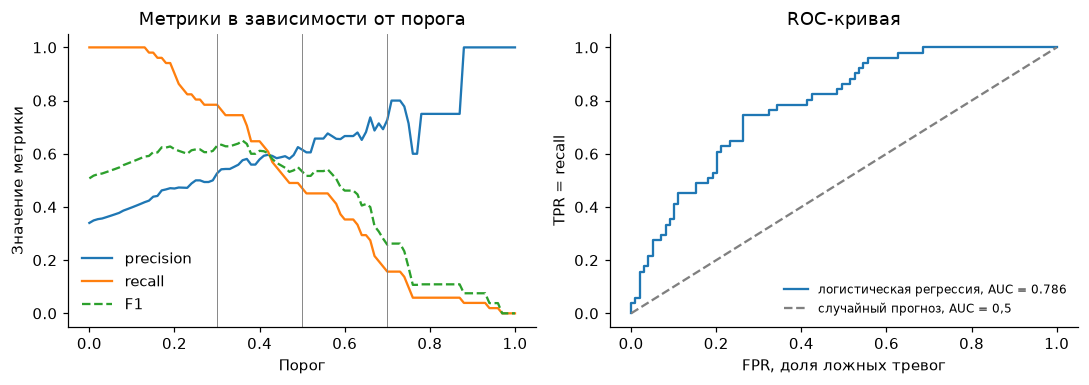

In [8]:
grid = np.linspace(0, 1, 101)
curves = {"precision": [], "recall": [], "F1": []}
for t in grid:
    p = (proba >= t).astype(int)
    curves["precision"].append(precision_score(y_test, p, zero_division=1))
    curves["recall"].append(recall_score(y_test, p))
    curves["F1"].append(f1_score(y_test, p))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name, style in [("precision", "-"), ("recall", "-"), ("F1", "--")]:
    axes[0].plot(grid, curves[name], style, label=name)
for t in [0.3, 0.5, 0.7]:
    axes[0].axvline(t, color="gray", lw=0.6)
axes[0].set_xlabel("Порог")
axes[0].set_ylabel("Значение метрики")
axes[0].legend(frameon=False)
axes[0].set_title("Метрики в зависимости от порога")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"логистическая регрессия, AUC = {roc_auc_score(y_test, proba):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="случайный прогноз, AUC = 0,5")
axes[1].set_xlabel("FPR, доля ложных тревог")
axes[1].set_ylabel("TPR = recall")
axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("ROC-кривая")
plt.tight_layout()
plt.show()

**Вывод.**
- Чем выше порог, тем осторожнее модель. Precision растёт, recall падает. При пороге 0,3 модель находит 78 % быстрых сделок, и F1 (0,63) выше, чем при 0,5 (0,533). При пороге 0,7 recall всего 0,157.
- Порог выбирает заказчик. Если ложная подсказка «сдастся» раздражает арендодателей, нужен высокий precision. Если важно не пропустить хорошие предложения, нужен высокий recall.
- ROC-AUC = 0,786 от порога не зависит. В 79 % случаев случайная быстро сданная квартира получает оценку выше, чем случайная несданная.
- Здесь порог исследуется на тесте только для наглядности. В реальном проекте порог подбирают на кросс-валидации через `cross_val_predict(..., method="predict_proba")`, а тест используют один раз в конце.

## Шаг 7. Сравнение моделей на кросс-валидации

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "logreg": LogisticRegression(),
    "knn": KNeighborsClassifier(n_neighbors=15),
    "tree": DecisionTreeClassifier(max_depth=4, random_state=42),
}
for name, clf in models.items():
    m = make_pipeline(prep, clf)
    f1 = cross_val_score(m, X_train, y_train, cv=5, scoring="f1").mean()
    auc = cross_val_score(m, X_train, y_train, cv=5, scoring="roc_auc").mean()
    print(f"{name:7} cv_f1 {f1:.3f}  cv_auc {auc:.3f}")

logreg  cv_f1 0.580  cv_auc 0.792
knn     cv_f1 0.252  cv_auc 0.588
tree    cv_f1 0.420  cv_auc 0.620


**Вывод.** Логистическая регрессия лучше по обеим метрикам: cv_f1 0,580 и cv_auc 0,792. У kNN 0,252 и 0,588, у дерева 0,420 и 0,620. На 450 объектах простая линейная модель обобщает лучше. kNN плохо работает при большом числе признаков, а дерево глубины 4 описывает цену за метр грубыми ступеньками. F1 = 0,58 всё ещё невысок из-за низкого recall. Это гипотеза для эксперимента в шаге 10.